California housing step by step
In this example we are going to predict the medium value of a district based in this data:
    MedInc - The middle income of the housing
    HousesAge - The middle ages of the housing
    AveRooms, AveBedrms - The medium number of bedrooms by house
    Population - The number of people
    AveOccup - The number medium of people by house
    Latitude, Longitude - The position of the district
    MedHouseVal - Objetive: medium value of the housing

First, we import the dataset as a frame and check the shape

In [1]:
from scipy.constants import alpha
from sklearn.datasets import fetch_california_housing

housing = fetch_california_housing(as_frame=True).frame
#housing = fetch_california_housing()
housing.shape

(20640, 9)

The we inspect the first 5 rows of the dataset

In [2]:
housing.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


And see the general data of each column within 2 decimals

In [3]:
housing.describe().round(2)

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00
mean,3.87,28.64,5.43,1.10,1425.48,3.07,35.63,-119.57,2.07
std,1.90,12.59,2.47,0.47,1132.46,10.39,2.14,2.00,1.15
min,0.50,1.00,0.85,0.33,3.00,0.69,32.54,-124.35,0.15
25%,2.56,18.00,4.44,1.01,787.00,2.43,33.93,-121.80,1.20
50%,3.53,29.00,5.23,1.05,1166.00,2.82,34.26,-118.49,1.80
75%,4.74,37.00,6.05,1.10,1725.00,3.28,37.71,-118.01,2.65
max,15.00,52.00,141.91,34.07,35682.00,1243.33,41.95,-114.31,5.00


Now we are going to vizualize the median house value by district
The problem is that, the censo register each district with value above 500_000 as 500_001, show a model cant be trainig
with this data because it cannot learn nothing above that limit

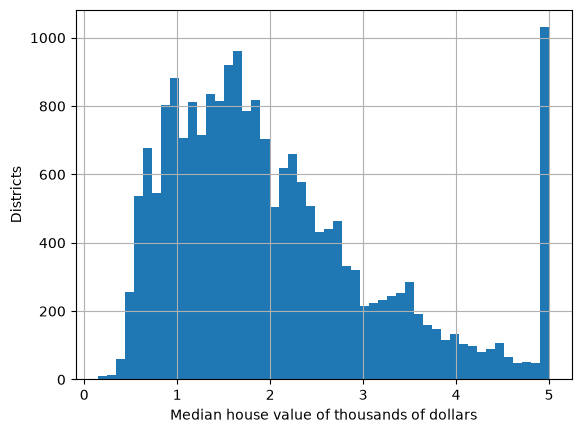

In [4]:
import matplotlib.pyplot as plt

housing['MedHouseVal'].hist(bins=50)
plt.xlabel('Median house value of thousands of dollars')
plt.ylabel('Districts')
plt.show()

## Correlation of each feature with the house value

The next line is a chain of steps, each one working on the result of the previous one:

1. **`housing.corr()`** calculates the **correlation** between every pair of columns and returns a 9×9 table. Correlation is a number from -1 to 1 that measures how closely two columns move together:
   - close to **1**: when one goes up, the other goes up (more income → more expensive houses)
   - close to **0**: no clear straight-line relationship
   - close to **-1**: when one goes up, the other goes down
2. **`['MedHouseVal']`** keeps only the column for the target, so we get each column's correlation with the house value.
3. **`.drop('MedHouseVal')`** removes the row for `MedHouseVal` itself. A column's correlation with itself is always exactly 1.0, so that row tells us nothing. This only drops a row from the result, not anything from the dataset.
4. **`.sort_values(ascending=False)`** sorts the features from the most positive to the most negative correlation, and **`.round(3)`** rounds them to 3 decimals.

### What the result says

- **`MedInc` (0.688)** is by far the strongest. Districts with higher incomes have more expensive houses.
- Everything else is close to 0, so none of the other features follow a straight-line relationship with the price.

> **Be careful:** correlation only detects **straight-line** relationships. `Latitude` (-0.144) and `Longitude` (-0.046) look almost useless, but location matters a lot in California. Coastal areas like San Francisco and Los Angeles are expensive, while inland areas are cheaper. That pattern isn't a straight line, so `corr` misses it. A low correlation doesn't mean a column is useless for the model, and a decision tree, for example, can still make good use of latitude and longitude.

In [5]:
housing.corr()['MedHouseVal'].drop('MedHouseVal').sort_values(ascending=False).round(3)

MedInc        0.688
AveRooms      0.152
HouseAge      0.106
AveOccup     -0.024
Population   -0.025
Longitude    -0.046
AveBedrms    -0.047
Latitude     -0.144
Name: MedHouseVal, dtype: float64

Now we devide the data by districts, we save an amount of districst that are not going to train the model
only to test it. Its important that, if we want to train a model to predict the MedHouseVal, we remove 
that property from de X and pass it like the y, so the model knows for each row of X there is a correlation to y

In [6]:
from sklearn.model_selection import train_test_split

X = housing.drop(columns='MedHouseVal')
y = housing['MedHouseVal'] 
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
X_train.shape, X_test.shape

((16512, 8), (4128, 8))

## Scaling the features with `StandardScaler`

`StandardScaler` puts every column on the same scale. It works in two steps.

**1. `.fit(X_train)` learns two numbers for each column**, looking at all the training rows at once:
- the **mean**: the average value of the column
- the **standard deviation**: how far the values usually are from the mean

These are calculated once per column, not per row. For example, `MedInc` has a mean of 3.88 and a standard deviation of 1.90. The table below shows the values for every column.

**2. `.transform(...)` uses those numbers to rescale every value in the column:**

```
scaled value = (value - mean) / standard deviation
```

The result says how many standard deviations a value is above or below the average. Every row in a column uses the same mean and standard deviation:

| District | MedInc | Scaled |
|---|---|---|
| A | 8.33 | (8.33 − 3.88) / 1.90 ≈ **2.34** |
| B | 7.57 | (7.57 − 3.88) / 1.90 ≈ **1.94** |

After scaling, every column has a mean of 0 and a standard deviation of 1.

### What the standard deviation is

A small example with a column of three values, 2, 4 and 6:
1. The mean is 4.
2. Each value's distance from the mean: −2, 0, +2.
3. Square the distances (4, 0, 4), take their average (8 / 3 ≈ 2.67), then the square root: **≈ 1.63**.

So a typical value is about 1.63 away from the mean. Squaring stops the negative and positive distances from cancelling each other out.

### Why we scale

The columns use very different units: `Population` is in the thousands, `AveBedrms` is around 1, `Latitude` is around 35. Large values don't cause an error, but some models give them too much importance just because they're bigger:
- models that measure distances, like k-nearest neighbours
- models trained step by step with gradient descent, like neural networks and `SGDRegressor`
- regularized linear models, like `Ridge` and `Lasso`

Scaling puts every column on the same footing, so the model judges each one by how useful it is, not by its units. Plain `LinearRegression` gives the same predictions with or without scaling, and decision trees don't care about scale at all.

### Why we fit only on `X_train`

The test set stands in for new data the model has never seen, so the mean and standard deviation must come from the training data only. If the test rows were included, information from the test set would leak into training and the test score would look better than it really is. Later we transform both sets with the same scaler:

```python
X_train_scaled = scaler.transform(X_train)
X_test_scaled = scaler.transform(X_test)
```

> Note: `AveOccup` has a standard deviation of 11.58 even though most values are around 3. That's because of a few extreme outliers (the max is 1243). `StandardScaler` is sensitive to outliers like that.

In [7]:
import pandas as pd
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler().fit(X_train)
pd.DataFrame({'mean': scaler.mean_, 'standard deviation': scaler.scale_}, index=X.columns).round(2)

,mean,standard deviation
MedInc,3.88,1.90
HouseAge,28.61,12.60
AveRooms,5.44,2.39
AveBedrms,1.10,0.43
Population,1426.45,1137.02
AveOccup,3.10,11.58
Latitude,35.64,2.14
Longitude,-119.58,2.01


### Checking the result: mean 0, standard deviation 1

After scaling, the values **above** and **below** the mean of each column cancel out, so the mean is 0. The rows aren't all the same distance from 0, but the *typical* distance (the standard deviation) is 1.

Small example with one column: 1, 2, 3, 10 (mean 4, standard deviation 3.54)

| Original | Scaled |
|---|---|
| 1 | −0.85 |
| 2 | −0.57 |
| 3 | −0.28 |
| 10 | +1.70 |

- Mean: −0.85 − 0.57 − 0.28 + 1.70 = **0**
- Standard deviation: √((0.72 + 0.32 + 0.08 + 2.88) / 4) = √1 = **1**

This happens down each column separately, not across a row. The next cell checks it on every column of `X_train`.

> `StandardScaler` divides by n (population standard deviation), not n − 1. pandas `.std()` divides by n − 1 by default, so we pass `ddof=0` to match the scaler. With 16,512 rows the difference is tiny anyway.

In [8]:
X_train_scaled = pd.DataFrame(scaler.transform(X_train), columns=X.columns, index=X_train.index)

pd.DataFrame({
    'mean before': X_train.mean(),
    'std before': X_train.std(ddof=0),
    'mean after': X_train_scaled.mean(),
    'std after': X_train_scaled.std(ddof=0),
}).round(2)

,mean before,std before,mean after,std after
MedInc,3.88,1.90,-0.0,1.0
HouseAge,28.61,12.60,-0.0,1.0
AveRooms,5.44,2.39,0.0,1.0
AveBedrms,1.10,0.43,-0.0,1.0
Population,1426.45,1137.02,0.0,1.0
AveOccup,3.10,11.58,0.0,1.0
Latitude,35.64,2.14,0.0,1.0
Longitude,-119.58,2.01,0.0,1.0


In [9]:
X_train_scaled = scaler.transform(X_train)
X_test_scaled = scaler.transform(X_test)

pd.DataFrame({
    'training mean': X_train_scaled.mean(axis=0),
    'training std': X_train_scaled.std(axis=0),
    'test mean': X_test_scaled.mean(axis=0),
    'test std': X_test_scaled.std(axis=0),
    }, index=X.columns).round(3)

,training mean,training std,test mean,test std
MedInc,-0.0,1.0,-0.026,0.988
HouseAge,-0.0,1.0,0.012,0.993
AveRooms,0.0,1.0,-0.013,1.171
AveBedrms,-0.0,1.0,-0.000,1.408
Population,0.0,1.0,-0.004,0.980
AveOccup,0.0,1.0,-0.011,0.151
Latitude,0.0,1.0,-0.026,0.998
Longitude,0.0,1.0,0.031,0.994


In [10]:
from sklearn.linear_model import LinearRegression

model = LinearRegression().fit(X_train_scaled, y_train)
pd.Series(model.coef_, index=X.columns).sort_values(key=abs, ascending=False).round(3)

Latitude     -0.897
Longitude    -0.870
MedInc        0.854
AveBedrms     0.339
AveRooms     -0.294
HouseAge      0.123
AveOccup     -0.041
Population   -0.002
dtype: float64

In [11]:
import numpy as np

unscaled_model = LinearRegression().fit(X_train, y_train)
#np.isclose(unscaled_model.predict(X_test), model.predict(X_test_scaled))
np.allclose(unscaled_model.predict(X_test), model.predict(X_test_scaled))

True

## Estimators, transformers and predictors

Every scikit-learn object follows the same pattern, so once we know these three roles we can use any of them.

- **Estimators:** any object that learns from data with `fit`. What it learns is saved in attributes whose names end in `_`, like `mean_` and `scale_` in the scaler, or `coef_` in the linear model.
  The settings we choose *before* it learns are called **hyperparameters**, and we pass them to the constructor, like `StandardScaler(with_mean=False)` or `DecisionTreeRegressor(max_depth=2)`.
- **Transformers:** estimators that change the data with `transform`. Examples are scalers (`StandardScaler`), imputers that fill missing values (`SimpleImputer`) and encoders that turn categories into numbers (`OneHotEncoder`).
  `fit_transform` does both steps on the same data: it learns from it and then transforms it. We only use it on the training rows. The test rows only get `transform`, so they're changed with what was learned from training.
- **Predictors:** estimators that make predictions with `predict`, like `LinearRegression` or `DecisionTreeRegressor`. They can also evaluate themselves with `score(X, y)`, which compares their predictions with the real values: for regression it returns the R², and for classification the accuracy.

An object can have more than one role: every transformer and predictor is also an estimator, because they all learn with `fit` first.

##Predict and measure the error
Here are the 3 measures of the error:
- MAE: Mean absolute error, is the mean distance from the prediction and the real value
- RMSE: Root mean squared error, is like the MAE but the big errors have more weight
- R2: Is the proportion of the objetive variance explaint in the model, 1 is a perfect model and 0 id a model that allways predict the mean

In [12]:
from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error

y_train_predicted = model.predict(X_train_scaled)
y_test_predicted = model.predict(X_test_scaled)

def error_measures(y_true, y_predicted):
    return {
            'MAE ($)': 100_000 * mean_absolute_error(y_true, y_predicted),
            'RMSE ($)': 100_000 * root_mean_squared_error(y_true, y_predicted),
            'R2': r2_score(y_true, y_predicted),
            }

pd.DataFrame({
    'y train': error_measures(y_train, y_train_predicted),
    'y test': error_measures(y_test, y_test_predicted)
    }).round(3)

,y train,y test
MAE ($),52862.836,53320.013
RMSE ($),71967.571,74558.138
R2,0.613,0.576


### How to read the R²

R² compares the model with the simplest possible guess: **always predicting the mean** house value, without looking at any feature.

```
R² = 1 − (model's error / error of always predicting the mean)
```

| R² | Meaning |
|---|---|
| **1** | perfect predictions: every error is 0 |
| **0** | no better than always predicting the mean |
| **negative** | worse than always predicting the mean |

- **It's a scale, not a yes/no answer.** Our test R² of 0.576 means the model removes about 58% of the error of always predicting the mean. That's useful even though it's far from 1. What counts as "good enough" depends on the problem.
- **The test R² is the one that matters.** An R² close to 1 on the training data is usually a sign of overfitting, like the unlimited tree in the overfitting notebook. Here the training R² (0.613) and the test R² (0.576) are close, so the model isn't overfitting.

Show the errors

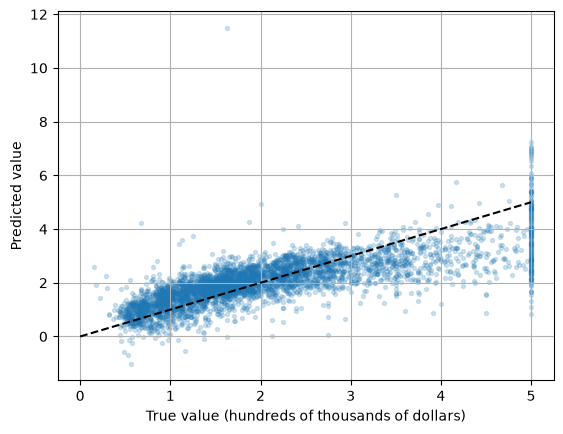

In [13]:
plt.scatter(y_test, y_test_predicted, alpha=0.2, s=8)
plt.plot([0,5], [0,5], 'k--')
plt.xlabel('True value (hundreds of thousands of dollars)')
plt.ylabel('Predicted value')
plt.grid(True)
plt.show()

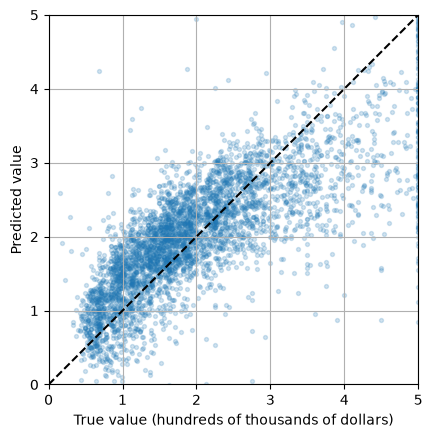

In [14]:
# Same chart, zoomed to 0-5 on both axes so the units match (points outside 0-5 are hidden)
plt.scatter(y_test, y_test_predicted, alpha=0.2, s=8)
plt.plot([0,5], [0,5], 'k--')
plt.xlim(0, 5)
plt.ylim(0, 5)
plt.gca().set_aspect('equal')
plt.xlabel('True value (hundreds of thousands of dollars)')
plt.ylabel('Predicted value')
plt.grid(True)
plt.show()

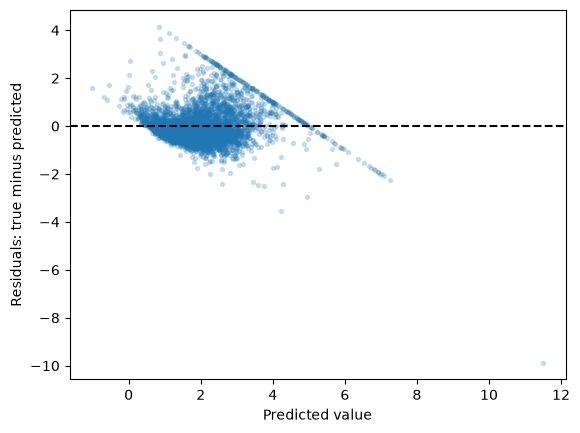

In [18]:
residuals = y_test - y_test_predicted
plt.scatter(y_test_predicted, residuals, alpha=0.2, s=8)
#plt.plot([0 ,12], [0,0], 'k--')
plt.axhline(0, color='k', linestyle='--')
plt.xlabel('Predicted value')
plt.ylabel('Residuals: true minus predicted')
plt.show()

### Reading the residuals

**Residual = real − predicted**, so each point is one district's error.
- Above 0: the model predicted too low.
- Below 0: the model predicted too high.
- The dashed line at 0 means no error.

**Why it matters:** MAE and R² say **how much** the model fails, while the residual plot shows **where and how**. A good model leaves a random cloud around 0. Any pattern is something the model hasn't learned.

**What this chart shows:**
1. **A diagonal stripe:** the $500,000 cap. Districts recorded as 5 line up artificially.
2. **A point near (11.5, −10):** one district overpredicted by almost $1 million, probably because of extreme feature values.
3. **Predictions below 0:** impossible negative prices. Linear regression has no limits.
4. **The cloud widens to the right:** the model is less reliable for expensive districts.

**Conclusion:** an R² of 0.576 says the model is "okay", and the residuals show why it isn't better and what to try next. Possible fixes: handle the cap and the outliers, or use a model that can bend, like a decision tree.